In [1]:
from pathlib import Path
import sys

project_root = next(
    (
        folder
        for folder in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if(folder / "src" / "analysis" / "common.py").is_file()
        and (folder / "data" / "raw").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.analysis.Payment_method_analysis import PaymentMethodAnalyzer
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
analyzer = PaymentMethodAnalyzer()

load_summary = analyzer.load_data()

print("payment methods shape: ", load_summary["payment_methods_shape"])
print("Transactions shape: ", load_summary["transactions_shape"])

payment methods shape:  (10000, 7)
Transactions shape:  (10000, 12)


In [3]:
print("payment method preview: ")
display(analyzer.payment_methods.head())

print("transactions preview: ")
display(analyzer.transactions.head())

print("\n Transactions status distribution: ")
display(analyzer.transactions["transaction_status"].value_counts(dropna=False))

payment method preview: 


,payment_method_id,customer_id,method_type,provider,last_four_digits,is_default,created_date
0,PM00001,CUST07008,Net Banking,ICICI Bank,6211.0,true,2024-12-19
1,PM00002,CUST03088,Debit Card,HDFC Bank,6337.0,false,2024-07-25
2,PM00003,CUST04595,Net Banking,SBI,3686.0,false,2023-06-07
3,PM00004,CUST05188,Debit Card,SBI,773.0,NaN,2024-04-12
4,NaN,CUST05725,Debit Card,SBI,8439.0,true,2024-10-31


transactions preview: 


,transaction_id,customer_id,merchant_id,payment_method_id,transaction_date,amount,currency,transaction_status,transaction_type,channel,city,state
0,TXN000001,CUST03136,MER03212,PM03707,2024-04-30 03:34:18,3497.58,INR,Success,Purchase,Mobile,Surat,Gujarat
1,TXN000002,CUST00249,MER04184,PM00989,2024-02-27 13:04:30,37124.66,INR,Success,Purchase,Mobile,Indore,Madhya Pradesh
2,TXN000003,CUST00727,MER03163,PM09518,2024-04-02 11:37:37,77539.12,INR,Success,Purchase,Mobile,Noida,UTTAR PRADESH
3,TXN000004,CUST07626,MER07052,PM08428,2024-07-20 23:39:05,78020.60,INR,Success,Purchase,Mobile,Chennai,Tamil Nadu
4,TXN000005,CUST04408,MER00136,PM00601,2024-07-12 09:45:01,43944.68,INR,success,Purchase,POS,Bengaluru,Karnataka



 Transactions status distribution: 


transaction_status
Success      7709
Failed       1113
Pending       540
success       149
NaN           149
 Success      137
SUCCESS       122
FAILED         19
 Failed        18
failed         13
 Pending       13
pending        10
PENDING         8
Name: count, dtype: int64

In [4]:
analysis_data = analyzer.merge_data()

print("transaction rows: ", len(analyzer.transactions))
print("joined rows: ", len(analysis_data))

print("\n join result: ")
display(analysis_data["_merge"].value_counts())

print("\nData Quality Summary:")
display(analyzer.check_data_quality())

transaction rows:  10000
joined rows:  10000

 join result: 


_merge
both          9459
left_only      541
right_only       0
Name: count, dtype: int64


Data Quality Summary:


,Data quality check,Count
0,Payment method source rows,10000
1,Transaction rows,10000
2,Exact duplicate payment method rows in source,115
3,Missing payment method IDs in source,148
4,Conflicting payment method IDs,1
5,Transactions with missing payment method ID,197
6,Unmatched transaction rows,541
7,Transactions with unknown status,149


In [5]:
payment_summary = analyzer.payment_method_summary()

display(payment_summary.sort_values("transaction_count", ascending=False,))

,method_type,provider,transaction_count,total_amount,average_amount,success_count,failure_count,success_rate_pct,failure_rate_pct
14,UPI,BHIM,1121,25870554.29,23583.002999,891,142,79.48,12.67
16,UPI,Paytm,1120,25403150.09,23369.963284,906,131,80.89,11.70
15,UPI,GooglePay,1102,24321657.60,22540.924560,893,129,81.03,11.71
17,UPI,PhonePe,1051,24996117.12,24244.536489,871,115,82.87,10.94
2,Credit Card,ICICI Bank,544,13118731.20,24752.323019,441,61,81.07,11.21
27,Unknown,Unknown,541,13613681.03,25686.190623,453,61,83.73,11.28
0,Credit Card,Axis Bank,503,11378783.47,22941.095706,411,52,81.71,10.34
8,Debit Card,SBI,498,11256095.98,22739.587838,413,54,82.93,10.84
5,Debit Card,Axis Bank,493,11307299.86,23266.049095,413,60,83.77,12.17
6,Debit Card,HDFC Bank,484,11388112.18,24076.347104,392,55,80.99,11.36


In [6]:
provider_summery = analyzer.provider_summary()

display(
    provider_summery.sort_values("transaction_count",ascending=False,)
)

,provider,transaction_count,total_amount,average_amount,success_count,failure_count,success_rate_pct,failure_rate_pct
4,ICICI Bank,1318,30300301.06,23580.000825,1056,155,80.12,11.76
7,SBI,1299,29893312.92,23299.542416,1059,146,81.52,11.24
3,HDFC Bank,1250,28141172.82,22934.941174,1001,149,80.08,11.92
5,Paytm,1141,25650292.35,23150.083348,923,133,80.89,11.66
1,BHIM,1130,25969931.66,23480.950868,897,144,79.38,12.74
2,GooglePay,1116,24596410.08,22503.577383,905,131,81.09,11.74
6,PhonePe,1060,25097962.89,24132.656625,880,115,83.02,10.85
0,Axis Bank,1002,22850986.87,23128.529221,827,114,82.53,11.38
8,Unknown,684,16904535.89,25306.191452,569,76,83.19,11.11


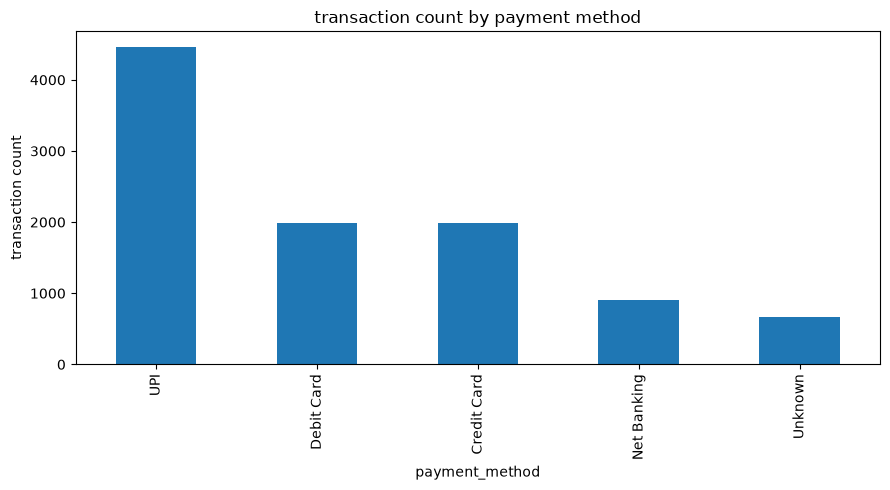

In [7]:
method_usage = (
    payment_summary.groupby("method_type")["transaction_count"].sum().sort_values(ascending=False)

)

method_usage.plot(kind="bar", figsize=(9,5))
plt.title("transaction count by payment method")
plt.xlabel("payment_method")
plt.ylabel("transaction count")
plt.tight_layout()
plt.show()

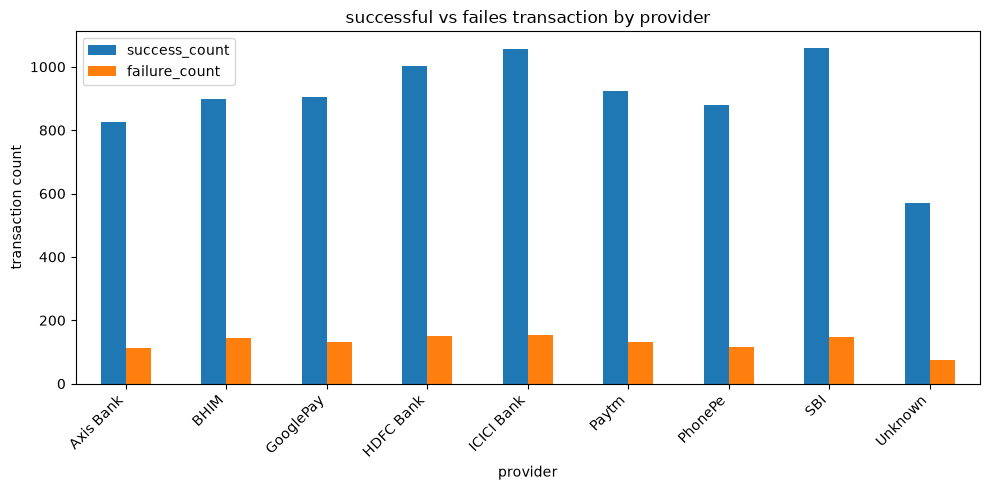

In [8]:
provider_summery.plot(x="provider", y=["success_count","failure_count"],kind="bar",figsize=(10, 5),)

plt.title("successful vs failes transaction by provider")
plt.xlabel("provider")
plt.ylabel("transaction count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


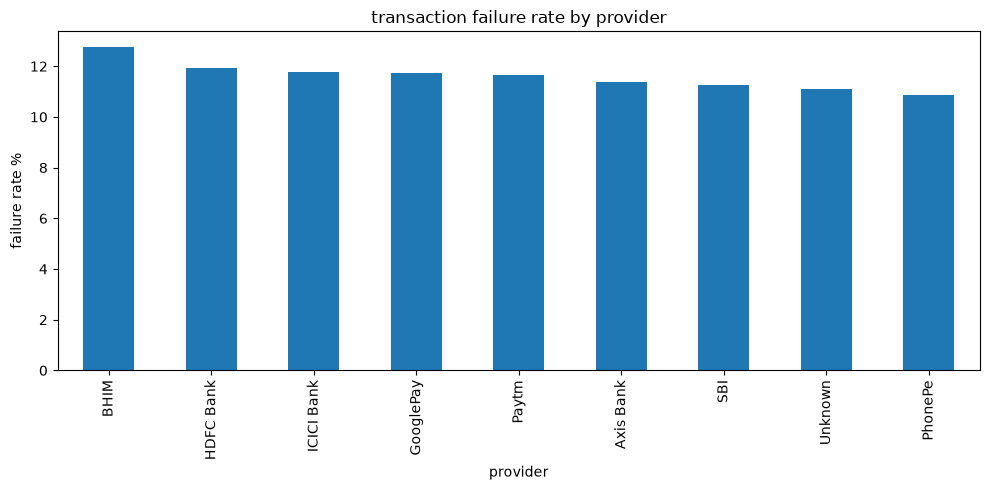

In [9]:
provider_failure = provider_summery.sort_values("failure_rate_pct", ascending=False,)

provider_failure.plot(
    x="provider",
    y="failure_rate_pct",
    kind="bar",
    legend=False,
    figsize=(10,5),
)

plt.title("transaction failure rate by provider")
plt.xlabel("provider")
plt.ylabel("failure rate %")
plt.tight_layout()
plt.show()

In [10]:
top_method = payment_summary.loc[
    payment_summary["transaction_count"].idxmax()
]

highest_amount = payment_summary.loc[
    payment_summary["total_amount"].idxmax()
]

highest_failure = payment_summary.loc[
    payment_summary["failure_rate_pct"].idxmax()
]

best_provider_success = provider_summery.loc[
    provider_summery["success_rate_pct"].idxmax()
]

quality_summary = analyzer.check_data_quality()
quality_lookup = quality_summary.set_index(
    "Data quality check"
)["Count"]

print("1. Highest transaction volume:")
print(
    f"{top_method['method_type']} / {top_method['provider']}: "
    f"{top_method['transaction_count']} transactions"
)

print("\n2. Highest total transaction amount:")
print(
    f"{highest_amount['method_type']} / {highest_amount['provider']}: "
    f"{highest_amount['total_amount']:.2f}"
)

print("\n3. Highest observed failure rate:")
print(
    f"{highest_failure['method_type']} / {highest_failure['provider']}: "
    f"{highest_failure['failure_rate_pct']:.2f}%"
)

print("\n4. Provider with the highest observed success rate:")
print(
    f"{best_provider_success['provider']}: "
    f"{best_provider_success['success_rate_pct']:.2f}%"
)

print("\n5. Data quality observations:")
print(
    "Unmatched transaction rows:",
    quality_lookup["Unmatched transaction rows"],
)
print(
    "Conflicting payment method IDs:",
    quality_lookup["Conflicting payment method IDs"],
)

1. Highest transaction volume:
UPI / BHIM: 1121 transactions

2. Highest total transaction amount:
UPI / BHIM: 25870554.29

3. Highest observed failure rate:
Unknown / Axis Bank: 33.33%

4. Provider with the highest observed success rate:
Unknown: 83.19%

5. Data quality observations:
Unmatched transaction rows: 541
Conflicting payment method IDs: 1


In [11]:
from src.analysis.common import save_report

save_report(payment_summary, "payment_method_summary.csv")
save_report(provider_summery, "provider_summary.csv")
save_report(quality_summary, "payment_method_data_quality.csv")

Report saved: C:\Users\Sanket Patil\Desktop\Payment-Transaction-Analytics-System\reports\payment_method_summary.csv
Report saved: C:\Users\Sanket Patil\Desktop\Payment-Transaction-Analytics-System\reports\provider_summary.csv
Report saved: C:\Users\Sanket Patil\Desktop\Payment-Transaction-Analytics-System\reports\payment_method_data_quality.csv


In [12]:
from pathlib import Path

reports_folder = project_root / "reports"

for file_name in [
    "payment_method_summary.csv",
    "provider_summary.csv",
    "payment_method_data_quality.csv",
]:
    file_path = reports_folder / file_name
    print(f"{file_name}: {'Created' if file_path.exists() else 'Not Found'}")

payment_method_summary.csv: Created
provider_summary.csv: Created
payment_method_data_quality.csv: Created


## Business Findings – Payment Method Analysis

### 1. BHIM has the highest transaction volume
The BHIM payment method recorded 1,121 transactions, the highest among the analyzed payment method and provider combinations. This indicates strong transaction usage and makes BHIM an important method to monitor.

### 2. BHIM recorded the highest total transaction amount
BHIM processed a total transaction amount of 25,870,554.29 in the analyzed dataset. This suggests that BHIM contributes significantly to the overall transaction value.

### 3. PhonePe showed a strong success rate among the leading UPI providers
PhonePe recorded a transaction success rate of 82.87%, with 871 successful transactions out of 1,051. This is a useful performance indicator when comparing the major UPI providers in this dataset.

### 4. Failure-rate comparisons should consider transaction volume
The highest observed failure rate was 33.33% for the Unknown payment method / Axis Bank group. However, this group contains only six transactions, so the rate is based on a small sample and should not be treated as conclusive evidence of poor provider performance.

### 5. Unmatched transaction records indicate a data quality issue
The analysis identified 541 transactions that did not match a payment method record. These records should be investigated because missing payment method details can reduce the reliability of provider-level reporting and business decisions.

### Conclusion
The analysis highlights differences in payment method usage, transaction value, and transaction outcomes. Improving payment method data quality and monitoring failure rates alongside transaction volumes can help produce more reliable payment performance insights.